# 03 — Outliers & skewness : de la détection à la décision

**Chaîne de raisonnement suivie pour chaque variable**

`détection statistique → interprétation → vérification métier → décision → justification → test de transformation → décision finale`


## 1. Chargement et audit général
Objectif : connaître la taille, les types, les valeurs manquantes, les doublons et le déséquilibre de la cible **avant** de parler d'outliers.

In [1]:

# 1. CHARGEMENT & AUDIT GÉNÉRAL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = '../data/train_final.csv'   # TRAIN uniquement (60 % du dataset)
TARGET = "Purchased"

df = pd.read_csv(DATA_PATH)
X_train = df.drop(columns=[TARGET])
y_train = df[TARGET]

print("Dimensions                 :", df.shape)
print("Valeurs manquantes (total) :", int(df.isna().sum().sum()))
print("Lignes dupliquées          :", int(df.duplicated().sum()))   # constat seulement : on ne supprime rien ici
print(f"Taux de positifs (cible)   : {y_train.mean():.2%}")
df.info()

Dimensions                 : (7020, 18)
Valeurs manquantes (total) : 0
Lignes dupliquées          : 0
Taux de positifs (cible)   : 15.34%
<class 'pandas.DataFrame'>
RangeIndex: 7020 entries, 0 to 7019
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   AdminPages       7020 non-null   int64  
 1   AdminTimeSec     7020 non-null   float64
 2   InfoPages        7020 non-null   int64  
 3   InfoTimeSec      7020 non-null   float64
 4   CatalogPages     7020 non-null   int64  
 5   CatalogTimeSec   7020 non-null   float64
 6   BounceRate       7020 non-null   float64
 7   ExitRate         7020 non-null   float64
 8   EngagementValue  7020 non-null   float64
 9   PromoProximity   7020 non-null   float64
 10  CampaignType     7020 non-null   str    
 11  DeviceOS         7020 non-null   int64  
 12  BrowserCode      7020 non-null   int64  
 13  GeoZone          7020 non-null   int64  
 14  EntryChannel     7020 non

**Interprétation**
- 7 020 lignes × 18 colonnes, **aucune valeur manquante** : un imputeur ne servira que si l'on transforme des valeurs invalides en `NaN`.
- La cible est déséquilibrée (≈ 15,3 % d'acheteurs) : les métriques de comparaison seront **ROC-AUC et PR-AUC** (average precision), pas l'accuracy.
- Une ligne « atypique » peut être une session très engagée donc potentiellement un acheteur : supprimer des lignes serait risqué pour la classe minoritaire.

## 2. Typologie des variables et contraintes métier

Seules les **10 variables quantitatives** sont analysées pour les outliers. Les colonnes `DeviceOS`, `BrowserCode`, `GeoZone`, `EntryChannel` sont stockées en entiers mais sont des **codes de modalités** (catégorielles) : un `BrowserCode = 13` n'est pas une « valeur extrême ». `CampaignType`, `CustomerType`, `Weekend` sont catégorielles/binaires.

In [2]:

numeric_cols = [
    "AdminPages", "AdminTimeSec", "InfoPages", "InfoTimeSec",
    "CatalogPages", "CatalogTimeSec", "BounceRate", "ExitRate",
    "EngagementValue", "PromoProximity",
]

count_cols    = ["AdminPages", "InfoPages", "CatalogPages"]           # comptages (entiers >= 0)
duration_cols = ["AdminTimeSec", "InfoTimeSec", "CatalogTimeSec"]     # durées en secondes (>= 0)
rate_cols     = ["BounceRate", "ExitRate"]                            # taux (0 <= x <= 0.2)
score_cols    = ["EngagementValue"]                                   # score continu >= 0, souvent null
discrete_cols = ["PromoProximity"]                                    # score discret borné entre 0 et 1
code_cols     = ["DeviceOS", "BrowserCode", "GeoZone", "EntryChannel"]  # codes catégoriels
cat_cols      = ["CampaignType", "CustomerType"]
binary_cols   = ["Weekend"]

# Contraintes DURES uniquement (min/max logiques par construction de la variable).
# Ne PAS y mettre de seuil statistique (type Tukey) : ce ne sont pas des contraintes métier.
CONSTRAINTS = {
    "AdminPages":      {"type": "comptage",       "min": 0, "max": 27, "entier": True},
    "InfoPages":       {"type": "comptage",       "min": 0, "max": 24, "entier": True},
    "CatalogPages":    {"type": "comptage",       "min": 0, "max": 650, "entier": True},
    "AdminTimeSec":    {"type": "durée (s)",      "min": 0, "max": None, "entier": False},
    "InfoTimeSec":     {"type": "durée (s)",      "min": 0, "max": None, "entier": False},
    "CatalogTimeSec":  {"type": "durée (s)",      "min": 0, "max": None, "entier": False},
    "BounceRate":      {"type": "taux",           "min": 0, "max": 0.2,    "entier": False},
    "ExitRate":        {"type": "taux",           "min": 0, "max": 0.2,    "entier": False},
    "EngagementValue": {"type": "score continu",  "min": 0, "max": None, "entier": False},
    "PromoProximity":  {"type": "score discret",  "min": 0, "max": 1,    "entier": False},
}


display(pd.DataFrame(CONSTRAINTS).T)

,type,min,max,entier
AdminPages,comptage,0,27,True
InfoPages,comptage,0,24,True
CatalogPages,comptage,0,650,True
AdminTimeSec,durée (s),0,None,False
InfoTimeSec,durée (s),0,None,False
CatalogTimeSec,durée (s),0,None,False
BounceRate,taux,0,0.2,False
ExitRate,taux,0,0.2,False
EngagementValue,score continu,0,None,False
PromoProximity,score discret,0,1,False


## 3. Distribution : forme, zéros, queue

On calcule pour chaque variable moyenne, médiane, quartiles, extrêmes, dispersion, **skewness**, **% de zéros**, et surtout la **skewness des seuls positifs** (`skew_positifs`). Cette dernière sépare deux phénomènes qu'il ne faut pas confondre :
- une **masse de zéros** (structure « zero-heavy ») ;
- une **vraie queue à droite parmi les valeurs positives**.

Les indicateurs `moy/med`, `max/Q3` et `z_max` donnent l'ampleur de la queue.

In [3]:

# 3. TABLE DE DISTRIBUTION

dist = X_train[numeric_cols].describe().T

dist["p99"] = X_train[numeric_cols].quantile(0.99)
dist["pct_zeros"] = (X_train[numeric_cols] == 0).mean() * 100
dist["skew"] = X_train[numeric_cols].skew()
dist["kurtosis_exces"] = X_train[numeric_cols].kurt()

# Skewness uniquement sur les valeurs positives
dist["skew_positifs"] = X_train[numeric_cols].apply(
    lambda s: s[s > 0].skew()
)

# Ratios
dist["moy/med"] = dist["mean"] / dist["50%"]
dist["max/Q3"] = dist["max"] / dist["75%"]

# Distance du maximum en écarts-types
dist["z_max"] = (dist["max"] - dist["mean"]) / dist["std"]

# Renommer les colonnes pour avoir des noms plus clairs
dist = dist.rename(columns={
    "mean": "moyenne",
    "50%": "mediane",
    "std": "ecart_type",
    "25%": "Q1",
    "75%": "Q3"
})

display(dist)

,count,moyenne,ecart_type,min,Q1,mediane,Q3,max,p99,pct_zeros,skew,kurtosis_exces,skew_positifs,moy/med,max/Q3,z_max
AdminPages,7020.0,2.331197,3.527253,0.0,0.000000,1.000000,3.000000,27.000,16.00000,44.259259,2.597363,9.295218,2.286294,2.331197,9.000000,6.993773
AdminTimeSec,7020.0,81.462782,208.131810,0.0,0.000000,14.620000,73.387500,3400.000,994.10340,44.259259,6.707099,66.173475,5.349963,5.572010,46.329416,15.944402
InfoPages,7020.0,0.511396,1.372189,0.0,0.000000,0.000000,0.000000,22.000,6.00000,76.980057,5.296978,44.243622,3.539471,inf,inf,15.660094
InfoTimeSec,7020.0,34.103249,146.719494,0.0,0.000000,0.000000,0.000000,2600.000,615.54110,76.980057,9.835225,130.181432,5.066630,inf,inf,17.488451
CatalogPages,7020.0,32.386467,47.568890,0.0,7.000000,18.000000,39.000000,650.000,225.43000,4.643875,4.694392,34.882535,4.660394,1.799248,16.666667,12.983560
CatalogTimeSec,7020.0,1107.169454,1984.089601,0.0,189.167500,500.765000,1197.042500,44164.740,9337.14410,4.643875,6.532662,75.047654,6.454973,2.210956,36.894881,21.701424
BounceRate,7020.0,0.019636,0.037878,0.0,0.000220,0.006225,0.020403,0.200,0.20000,23.746439,3.496555,12.985041,3.069104,3.154342,9.802720,4.761738
ExitRate,7020.0,0.046550,0.044359,0.0,0.017985,0.031970,0.056770,0.200,0.20000,1.524217,1.988019,3.810248,1.993512,1.456048,3.522987,3.459270
EngagementValue,7020.0,6.034811,15.289578,0.0,0.000000,0.000000,2.958250,181.762,72.53179,66.225071,4.046662,21.740686,2.328472,inf,61.442407,11.493266
PromoProximity,7020.0,0.060484,0.195066,0.0,0.000000,0.000000,0.000000,1.000,1.00000,89.330484,3.388596,10.724392,0.110850,inf,inf,4.816397


### Interprétation de la distribution des variables

L'analyse montre que la majorité des variables sont **asymétriques à droite** (`skew > 0`). Cela signifie que la plupart des observations prennent des valeurs faibles ou modérées, tandis qu'une minorité présente des valeurs beaucoup plus élevées, formant une longue queue à droite.

Plusieurs variables présentent également une **forte concentration de zéros** :
- `PromoProximity` : **89,33 %** de zéros ;
- `InfoPages` et `InfoTimeSec` : **76,98 %** ;
- `EngagementValue` : **66,23 %** ;
- `AdminPages` et `AdminTimeSec` : **44,26 %**.

Pour `InfoPages`, `InfoTimeSec`, `EngagementValue` et `PromoProximity`, les quartiles sont fortement concentrés à zéro (`Q1 = médiane = Q3 = 0` pour certaines variables). Les valeurs positives constituent donc une partie minoritaire des observations.

Les variables `AdminTimeSec`, `InfoTimeSec` et `CatalogTimeSec` présentent une asymétrie particulièrement forte. Par exemple, `InfoTimeSec` possède un `skew` de **9,84**, tandis que son `skew_positifs` atteint **130,18**. Cela montre que même parmi les valeurs positives, quelques observations sont beaucoup plus élevées que les autres.

Les variables `CatalogPages` et `CatalogTimeSec` contiennent peu de zéros, mais présentent également une longue queue droite. Par exemple, `CatalogPages` a une médiane de **18**, alors que son maximum atteint **650**.

Ainsi, les valeurs extrêmes détectées statistiquement ne doivent **pas être considérées automatiquement comme des erreurs**. Elles peuvent correspondre à des comportements rares mais légitimes. La décision concernant leur traitement doit donc être complétée par l'analyse des contraintes métier, du contexte des variables et des visualisations.

**Conclusion :** les distributions sont principalement caractérisées par une combinaison de **zéros fréquents, d'asymétrie positive et de valeurs extrêmes**. Ces caractéristiques devront être prises en compte avant toute décision de suppression ou de transformation des observations.

## 4. Tukey / IQR : ce que la méthode détecte, et pourquoi


In [4]:
outlier_mask = pd.DataFrame(
    False, index=X_train.index, columns=numeric_cols
)
summary = []

for col in numeric_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask[col] = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    )

    count = int(outlier_mask[col].sum())
    summary.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "borne_basse": lower_bound,
        "borne_haute": upper_bound,
        "nombre_outliers": count,
        "pourcentage": 100 * count / len(X_train),
    })

outlier_summary = (
    pd.DataFrame(summary).set_index("variable")
    .sort_values("nombre_outliers", ascending=False)
)

df_outliers = X_train[numeric_cols].where(outlier_mask)
df_outliers = df_outliers.loc[outlier_mask.any(axis=1)].copy()
df_outliers["nombre_variables_atypiques"] = (
    outlier_mask.sum(axis=1).loc[df_outliers.index]
)

display(outlier_summary)

,Q1,Q3,IQR,borne_basse,borne_haute,nombre_outliers,pourcentage
variable,,,,,,,
InfoTimeSec,0.000000,0.000000,0.000000,0.000000,0.000000,1616,23.019943
InfoPages,0.000000,0.000000,0.000000,0.000000,0.000000,1616,23.019943
EngagementValue,0.000000,2.958250,2.958250,-4.437375,7.395625,1361,19.387464
AdminTimeSec,0.000000,73.387500,73.387500,-110.081250,183.468750,798,11.367521
PromoProximity,0.000000,0.000000,0.000000,0.000000,0.000000,749,10.669516
CatalogTimeSec,189.167500,1197.042500,1007.875000,-1322.645000,2708.855000,674,9.601140
BounceRate,0.000220,0.020403,0.020182,-0.030054,0.050676,659,9.387464
ExitRate,0.017985,0.056770,0.038785,-0.040192,0.114948,562,8.005698
AdminPages,0.000000,3.000000,3.000000,-4.500000,7.500000,547,7.792023


**Résultats Tukey et interprétation**

| Variable | % détectés | Pourquoi Tukey en détecte autant / peu |
|---|---:|---|
| InfoTimeSec | 23,02 |  Q1 = Q3 = 0, IQR = 0, fence haute = 0 : **tout > 0 est détecté** ⇒ 76,98 % de zéros |
| InfoPages | 23,02 | idem |
| EngagementValue | 19,39 | Q1 = 0, médiane = 0 : l'IQR (2,96) est tiré par une partie seulement des positifs |
| AdminTimeSec | 11,37 |  Q1 = 0 ; fence haute ≈ 183 s (3 min) |
| PromoProximity | 10,67 |  IQR = 0 : détecte tous les niveaux non nuls ⇒ 89,33 % de zéros |
| CatalogTimeSec | 9,60 | IQR large (1 008) : détection interprétable, fence ≈ 2 709 s |
| BounceRate | 9,39 | échelle minuscule, pic à 0,2 ; fence 0,0507 |
| ExitRate | 8,01 | fence 0,115 ; pic à 0,2 |
| AdminPages | 7,79 | IQR = 3, fence 7,5 : ≥ 8 pages |
| CatalogPages | 7,58 | IQR = 32, fence 87 pages |

**Conclusions**
- Pour `InfoPages`, `InfoTimeSec`, `PromoProximity`, **le pourcentage Tukey ne mesure pas des anomalies**, il mesure la proportion de valeurs non nulles. Dire « 23 % d'outliers » serait faux : **les valeurs positives ne sont pas des outliers**, la variable est simplement très asymétrique.
- Pour `EngagementValue` et `AdminTimeSec`, la présence massive de zéros déforme l'IQR ; le seuil est arbitraire.
- Pour `AdminPages`, `CatalogPages`, `CatalogTimeSec`, la détection est interprétable (IQR non dégénéré) mais elle décrit une **queue**, pas des erreurs.
- Pour `BounceRate`/`ExitRate`, la fence tombe en plein milieu de la queue réelle et couperait le pic à 0,2.

## 5. Visualisation : boxplots, histogrammes avec bornes, positifs en échelle log

Le troisième graphique montre la distribution des **seuls valeurs positives** en `log1p` : il permet de voir si, une fois les zéros retirés, la forme est raisonnable (cloche) ou reste problématique.

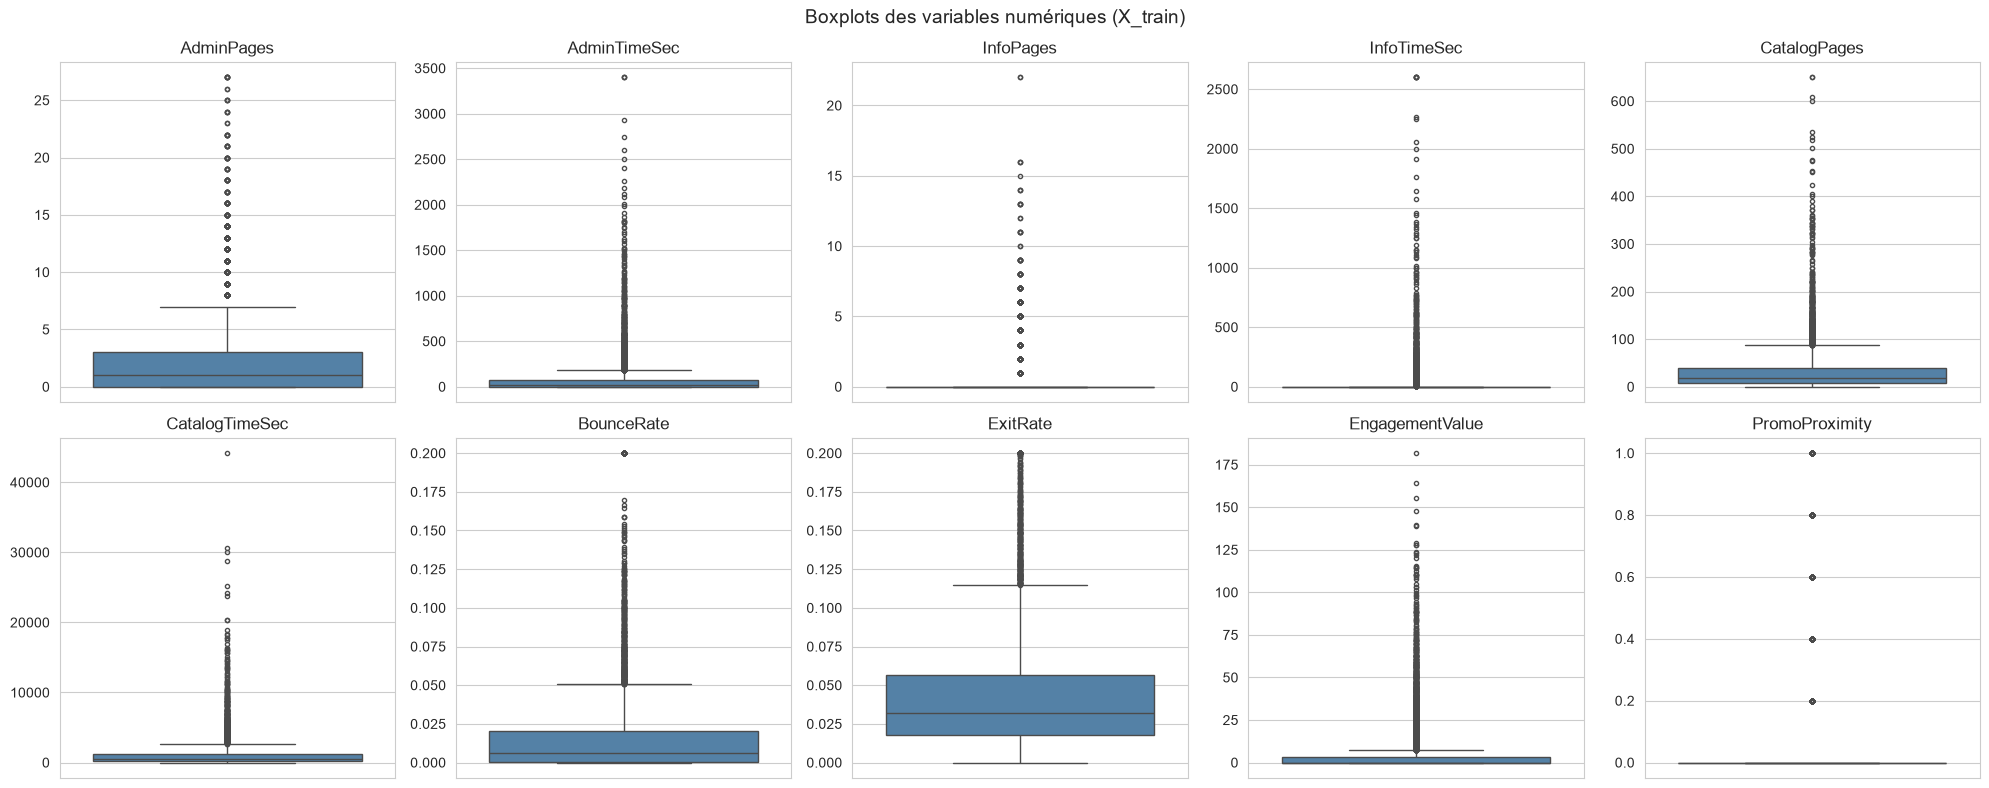

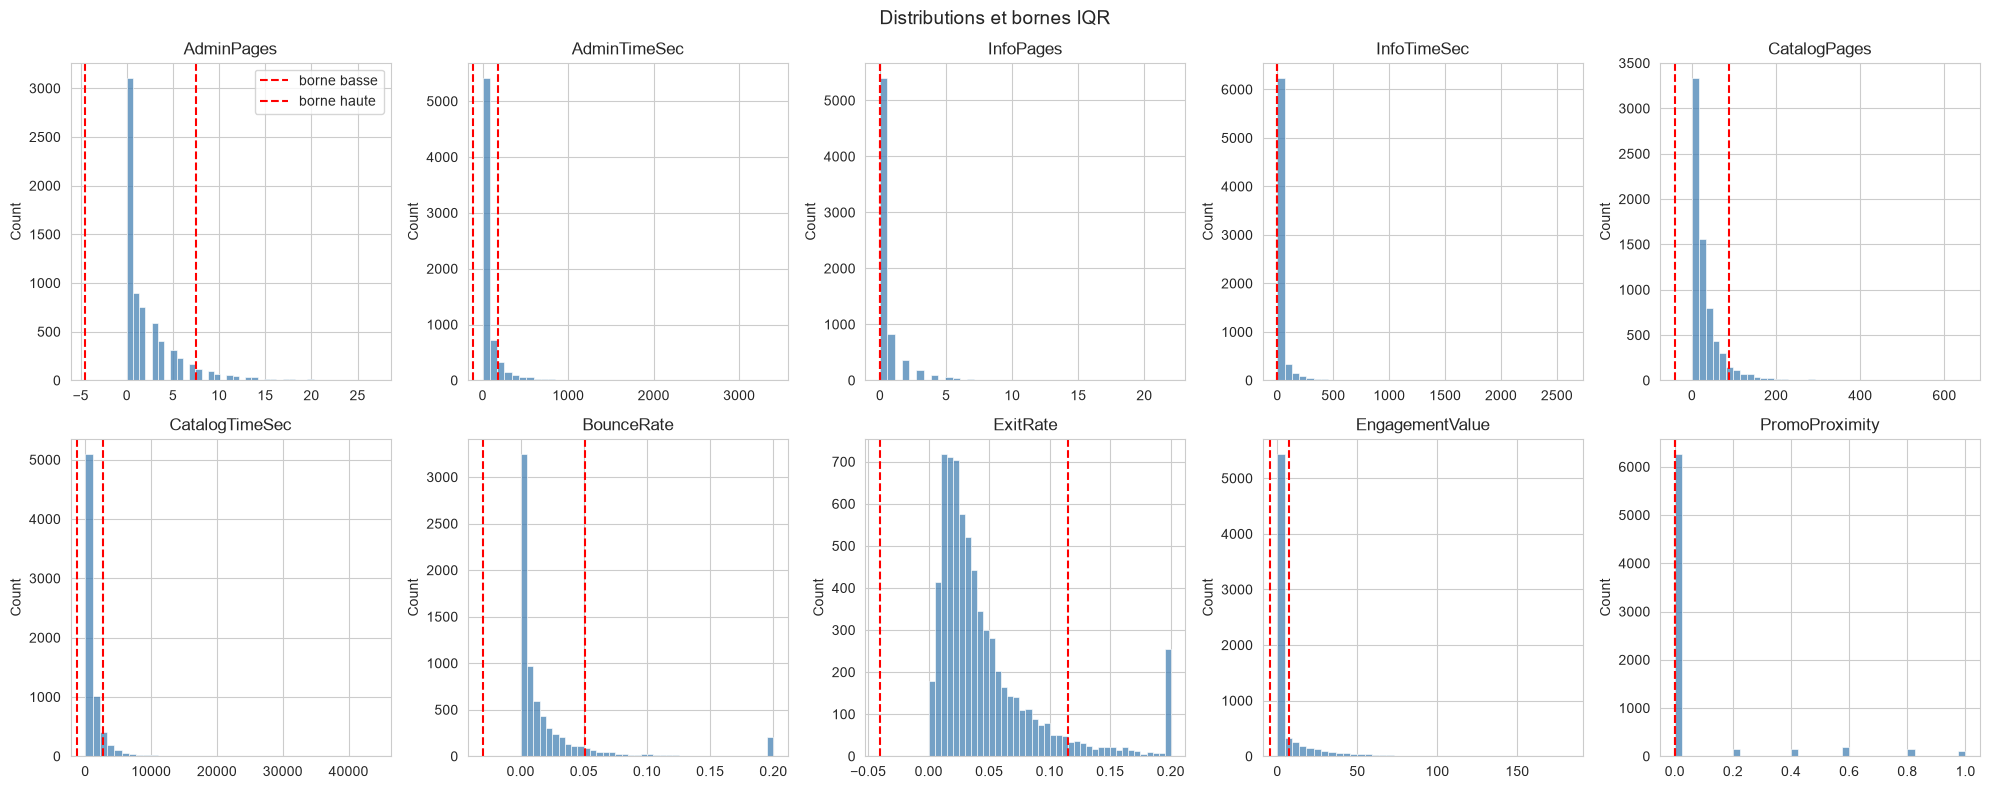

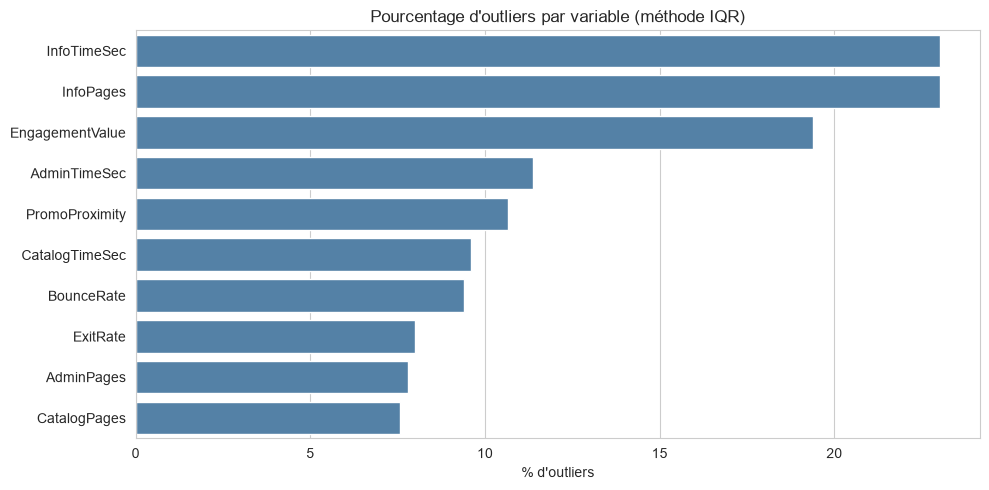

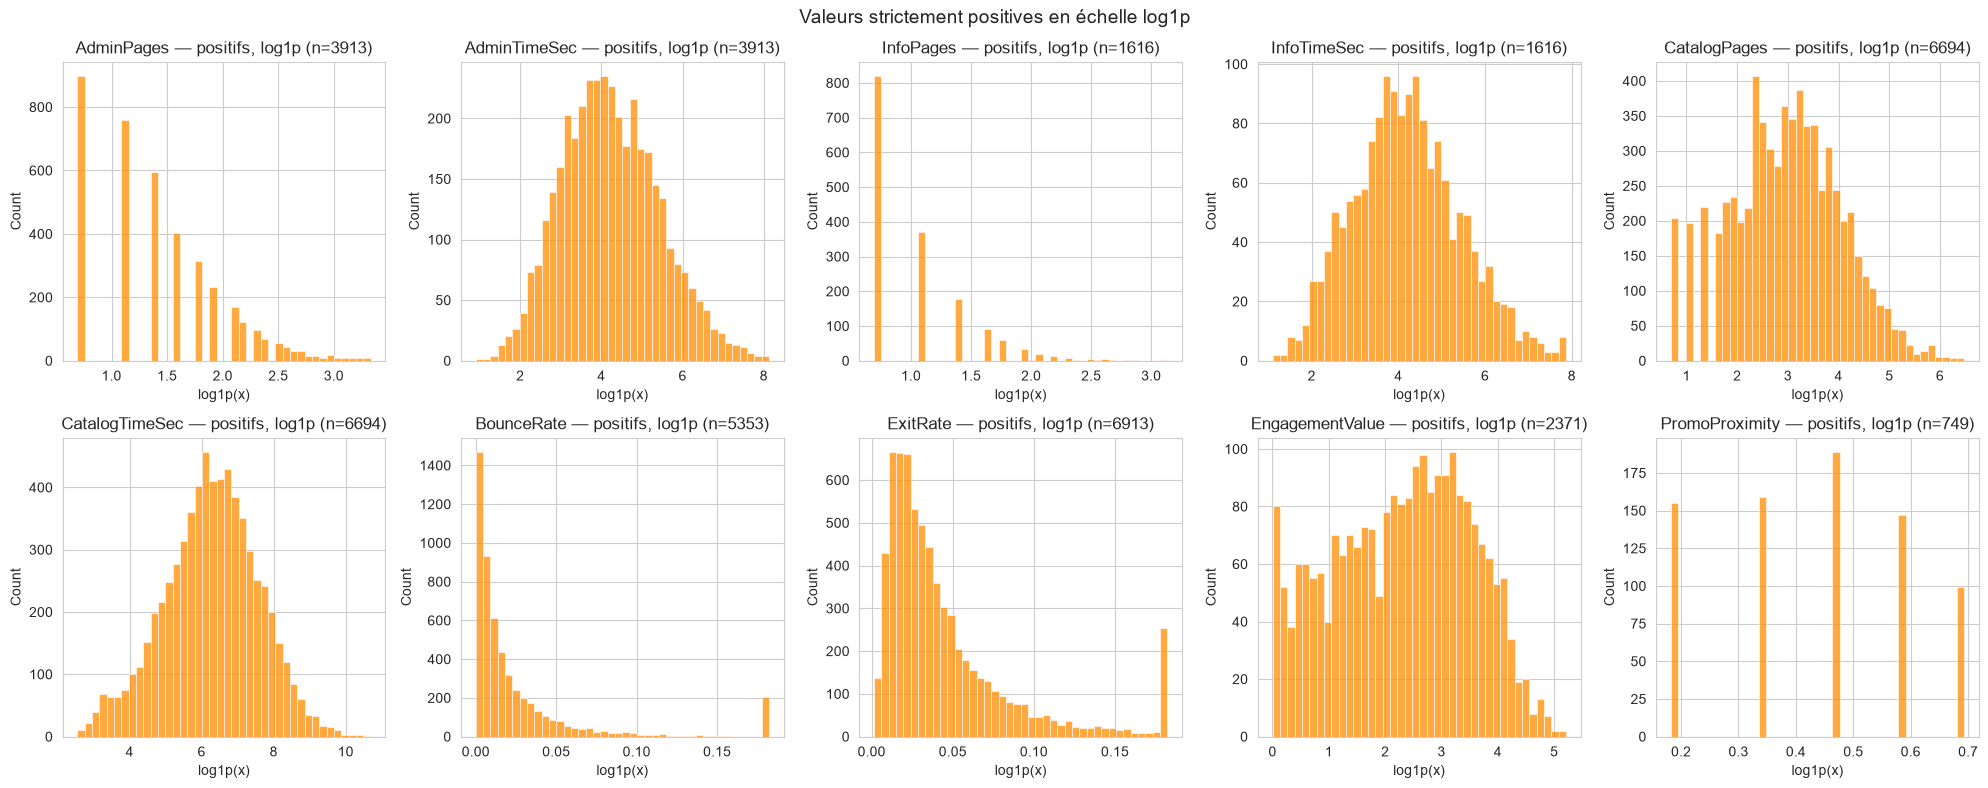

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Boxplots (un par variable)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=X_train[col], ax=ax, color="steelblue", flierprops={"markersize": 3})
    ax.set_title(col)
    ax.set_ylabel("")

plt.suptitle("Boxplots des variables numériques (X_train)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Histogrammes avec les bornes IQR
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    row = outlier_summary.loc[col]
    sns.histplot(X_train[col], bins=40, ax=ax, color="steelblue")
    ax.axvline(row["borne_basse"], color="red", linestyle="--", label="borne basse")
    ax.axvline(row["borne_haute"], color="red", linestyle="--", label="borne haute")
    ax.set_title(col)
    ax.set_xlabel("")

axes[0].legend()
plt.suptitle("Distributions et bornes IQR", fontsize=14)
plt.tight_layout()
plt.show()

# 3. Pourcentage d'outliers par variable
plt.figure(figsize=(10, 5))
sns.barplot(
    data=outlier_summary,
    x="pourcentage",
    y="variable",
    color="steelblue",
)
plt.xlabel("% d'outliers")
plt.ylabel("")
plt.title("Pourcentage d'outliers par variable (méthode IQR)")
plt.tight_layout()
plt.show()


# 4. Valeurs POSITIVES seulement, en échelle log1p : sépare « masse de zéros » et « queue »
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    pos = X_train.loc[X_train[col] > 0, col]
    sns.histplot(np.log1p(pos), bins=40, ax=ax, color="darkorange")
    ax.set_title(f"{col} — positifs, log1p (n={len(pos)})"); ax.set_xlabel("log1p(x)")
plt.suptitle("Valeurs strictement positives en échelle log1p", fontsize=14)
plt.tight_layout(); plt.show()

## Interprétation des visualisations

### 1. Boxplots des variables numériques

Les boxplots confirment la présence de nombreuses valeurs extrêmes pour la majorité des variables.

- `AdminPages` et `AdminTimeSec` présentent une forte concentration des observations dans les faibles valeurs, avec une longue série de valeurs élevées. Cela traduit une asymétrie à droite.
- `InfoPages` et `InfoTimeSec` ont une boîte quasiment confondue avec zéro et de nombreuses observations éloignées vers les valeurs positives. Cette structure est cohérente avec leur forte proportion de zéros.
- `CatalogPages` et `CatalogTimeSec` présentent également une longue queue vers les grandes valeurs, mais avec une concentration moins importante sur zéro.
- `BounceRate` et `ExitRate` montrent une distribution asymétrique avec plusieurs valeurs élevées. Pour `ExitRate`, les valeurs sont toutefois davantage réparties sur une plage intermédiaire.
- `EngagementValue` présente une forte concentration autour de zéro, accompagnée de nombreuses valeurs positives élevées.
- `PromoProximity` est très particulière : la grande majorité des observations sont à zéro et les valeurs non nulles sont discrètes et limitées à quelques niveaux.

Les nombreux points situés au-delà des moustaches correspondent à des **valeurs statistiquement atypiques selon la règle de Tukey**, mais ils ne constituent pas nécessairement des erreurs de données.

---

### 2. Distributions et bornes IQR

Les histogrammes confirment les observations des boxplots.

La plupart des variables présentent une **asymétrie positive** : les observations sont concentrées sur les faibles valeurs et une queue s'étend vers les grandes valeurs.

Pour `AdminPages`, `AdminTimeSec`, `InfoPages`, `InfoTimeSec`, `CatalogPages`, `CatalogTimeSec` et `EngagementValue`, les distributions sont fortement étirées vers la droite.

`InfoPages`, `InfoTimeSec`, `EngagementValue` et `PromoProximity` présentent en plus une très forte concentration de zéros. Les bornes IQR sont donc fortement influencées par cette concentration et peuvent classer une grande partie des valeurs positives comme atypiques.

Pour `BounceRate` et `ExitRate`, les valeurs sont comprises dans des intervalles relativement limités, mais présentent également une queue droite.

Ainsi, la détection IQR doit être interprétée avec prudence pour ces variables : une observation située au-delà de la borne supérieure n'est pas automatiquement une observation incorrecte.

---

### 3. Valeurs strictement positives en échelle `log1p`

L'analyse des seules valeurs strictement positives permet de mieux observer la structure des distributions sans que les zéros dominent les graphiques.

Après transformation `log1p`, certaines distributions deviennent plus compactes et plus proches d'une forme régulière :

- `AdminTimeSec` et `CatalogTimeSec` présentent une distribution positive relativement étalée, avec une concentration centrale.
- `InfoTimeSec` présente également une forme relativement régulière après transformation, malgré la forte asymétrie observée sur l'échelle originale.
- `CatalogPages` devient plus équilibrée après transformation, ce qui confirme que les grandes valeurs sont principalement responsables de l'asymétrie initiale.
- `BounceRate` et `ExitRate` restent asymétriques, avec une concentration importante dans les faibles valeurs.
- `EngagementValue` présente une distribution positive beaucoup plus étalée et moins dominée par les très grandes valeurs après transformation.
- `PromoProximity` reste discrète : les valeurs positives apparaissent sous forme de quelques niveaux distincts. Il ne s'agit donc pas d'une variable continue classique.

Pour `AdminPages` et `InfoPages`, la présence de plusieurs pics après suppression des zéros indique que les valeurs positives sont également concentrées sur certains niveaux.

Cette transformation ne sert ici qu'à **mieux visualiser la structure des valeurs positives** ; elle ne signifie pas que les données doivent nécessairement être transformées de cette manière dans le modèle final.

---

### Conclusion des visualisations

Les différentes visualisations convergent vers le même constat : les variables numériques présentent principalement des **distributions asymétriques à droite**, avec une concentration importante de zéros pour certaines variables et des queues contenant des valeurs élevées.

La règle de Tukey permet d'identifier des observations statistiquement atypiques, mais elle ne permet pas à elle seule de déterminer si ces observations sont anormales.

La décision de conserver, transformer ou traiter ces valeurs doit donc être basée sur :
1. la distribution de la variable ;
2. la proportion de zéros ;
3. les contraintes et bornes métier ;
4. le comportement des valeurs positives ;
5. et, lorsque cela est pertinent, leur relation avec la variable cible.

**Ainsi, les outliers détectés dans cette analyse sont considérés comme des observations à examiner et non comme des valeurs à supprimer automatiquement.**

## 6. Vérification métier : valeurs impossibles, extrêmes plausibles, indéterminables

On distingue :

| Catégorie | Définition | Traitement automatique ? |
|---|---|---|
| **A** | Impossible selon une contrainte explicite (ex. comptage négatif) | Oui, seulement ces cas |
| **B** | Extrême mais plausible | Non |
| **C** | Rare mais normale | Non |
| **D** | Validité indéterminable avec les informations disponibles | Non : on flagge et on documente |


In [6]:

# 6.1 CATÉGORIE A 
def hard_constraint_violations(X):
    rows = []
    for c, r in CONSTRAINTS.items():
        s = X[c]
        n_below = int((s < r["min"]).sum()) if r["min"] is not None else 0
        n_above = int((s > r["max"]).sum()) if r["max"] is not None else 0
        n_nonint = int((s % 1 != 0).sum()) if r["entier"] else 0
        rows.append({"variable": c, "type": r["type"],
                     "n_sous_min": n_below, "n_sur_max": n_above, "n_non_entiers": n_nonint,
                     "n_A_total": n_below + n_above + n_nonint})
    return pd.DataFrame(rows).set_index("variable")

hard = hard_constraint_violations(X_train)
display(hard)
print("Total de valeurs impossibles (catégorie A) :", int(hard["n_A_total"].sum()))

,type,n_sous_min,n_sur_max,n_non_entiers,n_A_total
variable,,,,,
AdminPages,comptage,0,0,0,0
InfoPages,comptage,0,0,0,0
CatalogPages,comptage,0,0,0,0
AdminTimeSec,durée (s),0,0,0,0
InfoTimeSec,durée (s),0,0,0,0
CatalogTimeSec,durée (s),0,0,0,0
BounceRate,taux,0,0,0,0
ExitRate,taux,0,0,0,0
EngagementValue,score continu,0,0,0,0


Total de valeurs impossibles (catégorie A) : 0


In [7]:

# 6.2 COHÉRENCES ENTRE VARIABLES 
PAIRS = [("AdminPages", "AdminTimeSec"), ("InfoPages", "InfoTimeSec"), ("CatalogPages", "CatalogTimeSec")]

rows = []
for p, t in PAIRS:
    time_without_pages = (X_train[p] == 0) & (X_train[t] > 0)   # durée positive sans page 
    pages_without_time = (X_train[p] > 0) & (X_train[t] == 0)   
    rows.append({"contrôle": f"{t} > 0 alors que {p} = 0", "n": int(time_without_pages.sum())})
    rows.append({"contrôle": f"{p} > 0 alors que {t} = 0", "n": int(pages_without_time.sum())})

coherence = pd.DataFrame(rows)
display(coherence)


,contrôle,n
0,AdminTimeSec > 0 alors que AdminPages = 0,0
1,AdminPages > 0 alors que AdminTimeSec = 0,0
2,InfoTimeSec > 0 alors que InfoPages = 0,0
3,InfoPages > 0 alors que InfoTimeSec = 0,0
4,CatalogTimeSec > 0 alors que CatalogPages = 0,0
5,CatalogPages > 0 alors que CatalogTimeSec = 0,0


In [8]:

# 6.3 PLAFONDS ET EXTRÊMES : où regarder pour les catégories B/C/D ?
# (a) Les taux sont-ils plafonnés à leur maximum observé ?
for c in rate_cols:
    mx = X_train[c].max()
    n_at_max = int((X_train[c] == mx).sum())
    print(f"{c}: max = {mx:.4f} ; {n_at_max} lignes ({100*n_at_max/len(X_train):.2f} %) exactement au max"
          f" -> pas un plafond ")

# (b) Niveaux de PromoProximity
print("\nPromoProximity — niveaux distincts :", np.sort(X_train["PromoProximity"].unique()))

# (c) Triage : combien de valeurs détectées sont réellement extrêmes ?
p995 = X_train[numeric_cols].quantile(0.995)
triage = pd.DataFrame({
    "n_detectees_Tukey":         outlier_summary["nombre_outliers"],
    "n_A_contraintes_dures":     hard["n_A_total"],
    "n_au_dessus_p99.5":         (X_train[numeric_cols] > p995).sum(),                          # extrêmes à revoir (D ?)
    "n_detectees_sous_p99.5":    (outlier_mask & (X_train[numeric_cols] <= p995)).sum(),         # détectées par Tukey mais pas parmi les 0,5 % les plus élevées
}).loc[numeric_cols]
display(triage)

# (d) Les 5 plus grandes valeurs de chaque variable, en multiples de Q3
tops = {}
for c in numeric_cols:
    q3 = X_train[c].quantile(0.75)
    top = X_train[c].nlargest(5)
    tops[c] = [f"{v:g}" + (f" (x{v/q3:.0f} Q3)" if q3 > 0 else "") for v in top]
display(pd.DataFrame(tops, index=[f"top{i}" for i in range(1, 6)]).T)

# (e) Cas extrêmes du catalogue : durée par page (une durée très élevée avec peu de pages est suspecte,
#     une durée élevée avec beaucoup de pages est cohérente)
tmp = X_train.assign(sec_par_page=X_train["CatalogTimeSec"] / X_train["CatalogPages"].replace(0, np.nan))
print("\nSecondes par page (Catalogue) — résumé")
print(tmp["sec_par_page"].describe().round(2).to_string())
print("\n10 plus longues durées catalogue :")
display(tmp.nlargest(10, "CatalogTimeSec")[["CatalogPages", "CatalogTimeSec", "sec_par_page"]])
print("10 plus grands nombres de pages catalogue :")
display(tmp.nlargest(10, "CatalogPages")[["CatalogPages", "CatalogTimeSec", "sec_par_page"]])

BounceRate: max = 0.2000 ; 203 lignes (2.89 %) exactement au max -> pas un plafond 
ExitRate: max = 0.2000 ; 246 lignes (3.50 %) exactement au max -> pas un plafond 

PromoProximity — niveaux distincts : [0.  0.2 0.4 0.6 0.8 1. ]


,n_detectees_Tukey,n_A_contraintes_dures,n_au_dessus_p99.5,n_detectees_sous_p99.5
AdminPages,547,0,33,514
AdminTimeSec,798,0,36,762
InfoPages,1616,0,32,1584
InfoTimeSec,1616,0,36,1580
CatalogPages,532,0,35,497
CatalogTimeSec,674,0,36,638
BounceRate,659,0,0,659
ExitRate,562,0,0,562
EngagementValue,1361,0,36,1325
PromoProximity,749,0,0,749


,top1,top2,top3,top4,top5
AdminPages,27 (x9 Q3),27 (x9 Q3),27 (x9 Q3),27 (x9 Q3),27 (x9 Q3)
AdminTimeSec,3400 (x46 Q3),3400 (x46 Q3),3400 (x46 Q3),2928.35 (x40 Q3),2746.01 (x37 Q3)
InfoPages,22,22,16,16,16
InfoTimeSec,2600,2600,2600,2600,2600
CatalogPages,650 (x17 Q3),650 (x17 Q3),609 (x16 Q3),600 (x15 Q3),536 (x14 Q3)
CatalogTimeSec,44164.7 (x37 Q3),30692.7 (x26 Q3),30061.7 (x25 Q3),28809 (x24 Q3),25178 (x21 Q3)
BounceRate,0.2 (x10 Q3),0.2 (x10 Q3),0.2 (x10 Q3),0.2 (x10 Q3),0.2 (x10 Q3)
ExitRate,0.2 (x4 Q3),0.2 (x4 Q3),0.2 (x4 Q3),0.2 (x4 Q3),0.2 (x4 Q3)
EngagementValue,181.762 (x61 Q3),164.239 (x56 Q3),155.327 (x53 Q3),147.901 (x50 Q3),139.601 (x47 Q3)
PromoProximity,1,1,1,1,1



Secondes par page (Catalogue) — résumé
count    6694.00
mean       31.04
std        11.48
min         8.04
25%        22.89
50%        29.09
75%        37.05
max       101.04

10 plus longues durées catalogue :


,CatalogPages,CatalogTimeSec,sec_par_page
4042,525,44164.74,84.123314
2289,609,30692.69,50.398506
4519,502,30061.66,59.883785
5843,519,28808.99,55.508651
6824,600,25177.99,41.963317
4149,650,24263.73,37.328815
5017,476,23825.21,50.052962
5785,650,20348.94,31.306062
4575,424,20290.65,47.855307
5431,400,18846.48,47.116200


10 plus grands nombres de pages catalogue :


,CatalogPages,CatalogTimeSec,sec_par_page
4149,650,24263.73,37.328815
5785,650,20348.94,31.306062
2289,609,30692.69,50.398506
6824,600,25177.99,41.963317
5026,536,9970.35,18.601399
4042,525,44164.74,84.123314
5843,519,28808.99,55.508651
4519,502,30061.66,59.883785
5017,476,23825.21,50.052962
5838,474,17814.26,37.582827


# Interprétation des valeurs extrêmes

La détection par la méthode de Tukey identifie un nombre important de valeurs extrêmes pour plusieurs variables. Cependant, **aucune ne viole les contraintes métier définies**. Ces détections doivent donc être interprétées comme des observations rares, et non automatiquement comme des erreurs.

Par exemple, `InfoPages` et `InfoTimeSec` présentent un nombre élevé de valeurs détectées par Tukey, alors que très peu dépassent le **99.5e percentile**. Cela suggère que la distribution est fortement asymétrique et que l'IQR est particulièrement sensible à sa forme.

Pour `BounceRate` et `ExitRate`, la valeur maximale de **0.20** est atteinte par plusieurs observations, mais cette concentration ne suffit pas à conclure à un plafonnement artificiel. De même, `PromoProximity` ne prend que des valeurs discrètes entre 0 et 1 ; la valeur `1` représente simplement le niveau maximal de la variable.

Le cas de `CatalogTimeSec` illustre également l'importance du contexte. L'observation la plus élevée atteint environ **44 165 secondes**, mais elle correspond à **525 pages consultées**, soit environ **84 secondes par page**. D'autres observations dépassent également plusieurs centaines de pages. Ces valeurs représentent donc des sessions très longues et intensives, mais aucune règle métier ne permet de les considérer comme impossibles.

Ainsi, les valeurs extrêmes identifiées sont **conservées**. Elles peuvent correspondre à des comportements rares mais plausibles. Leur suppression ou leur imputation ne serait pas justifiée uniquement par un critère statistique. Une attention particulière sera toutefois portée à leur influence lors des étapes de transformation et de modélisation.

## 7. Lien avec la cible : signal ou bruit ?

Avant tout clipping, il faut savoir si les valeurs « atypiques » portent de l'information sur `Purchased`.
- Si les lignes détectées ont un **taux d'achat très différent** du reste, elles contiennent du **signal** : les écraser le détruirait.
- L'**AUC univariée** est calculée sur les rangs : elle est **invariante à toute transformation monotone** (`log1p` ne la change pas). Une transformation n'aide donc que via le *modèle*, pas via le pouvoir discriminant de la variable.
- Une AUC univariée **extrêmement élevée** sur une variable (typiquement `EngagementValue`) est un signal d'alerte : vérifier dans le dictionnaire comment elle est construite (fuite possible).

In [9]:
# =====================================================================
# 7. LIEN AVEC LA CIBLE (calculé sur le TRAIN)
# =====================================================================
from sklearn.metrics import roc_auc_score

rows = []
for c in numeric_cols:
    s = X_train[c]
    flagged = outlier_mask[c]
    rows.append({
        "variable": c,
        "auc_univariee": roc_auc_score(y_train, s),
        "taux_achat_detectes": y_train[flagged].mean() if flagged.any() else np.nan,
        "taux_achat_non_detectes": y_train[~flagged].mean(),
        "taux_achat_zero": y_train[s == 0].mean() if (s == 0).any() else np.nan,
        "taux_achat_positifs": y_train[s > 0].mean() if (s > 0).any() else np.nan,
    })
target_link = pd.DataFrame(rows).set_index("variable")
print(f"Taux d'achat global : {y_train.mean():.3f}")
display(target_link)

# Au niveau de la ligne : les lignes à ≥ 1 variable détectée achètent-elles plus ?
flag_any = outlier_mask.any(axis=1)
print("\nTaux d'achat selon « ligne avec ≥ 1 variable détectée » :")
display(y_train.groupby(flag_any).agg(["mean", "count"]))
print("Taux d'achat selon le nombre de variables atypiques :")
display(y_train.groupby(outlier_mask.sum(axis=1)).agg(["mean", "count"]))

# Découpage des valeurs positives en quartiles pour les variables clés (forme de la relation)
for c in ["EngagementValue", "CatalogPages", "CatalogTimeSec", "PromoProximity"]:
    pos = X_train[c] > 0
    if pos.sum() > 20:
        bins = pd.qcut(X_train.loc[pos, c], q=4, duplicates="drop")
        print(f"\n{c} : taux d'achat par quartile des valeurs POSITIVES (zéros exclus)")
        print(y_train[pos].groupby(bins).agg(["mean", "count"]).to_string())

Taux d'achat global : 0.153


,auc_univariee,taux_achat_detectes,taux_achat_non_detectes,taux_achat_zero,taux_achat_positifs
variable,,,,,
AdminPages,0.565145,0.246801,0.145528,0.130673,0.171480
AdminTimeSec,0.569996,0.243108,0.141916,0.130673,0.171480
InfoPages,0.525071,0.180074,0.145448,0.145448,0.180074
InfoTimeSec,0.526494,0.180074,0.145448,0.145448,0.180074
CatalogPages,0.692542,0.315789,0.140105,0.018405,0.159994
CatalogTimeSec,0.688691,0.310089,0.136779,0.018405,0.159994
BounceRate,0.393627,0.022762,0.166955,0.175765,0.146460
ExitRate,0.323450,0.019573,0.165067,0.140187,0.153624
EngagementValue,0.739332,0.396767,0.094893,0.072274,0.312526



Taux d'achat selon « ligne avec ≥ 1 variable détectée » :


,mean,count
False,0.096785,2893
True,0.193118,4127


Taux d'achat selon le nombre de variables atypiques :


,mean,count
0,0.096785,2893
1,0.202326,1290
2,0.122998,1561
3,0.246439,702
4,0.218750,352
5,0.407407,162
6,0.476190,42
7,0.444444,18



EngagementValue : taux d'achat par quartile des valeurs POSITIVES (zéros exclus)
                       mean  count
EngagementValue                   
(0.0, 2.758]       0.166948    593
(2.758, 10.029]    0.247892    593
(10.029, 24.689]   0.342905    592
(24.689, 181.762]  0.492411    593

CatalogPages : taux d'achat par quartile des valeurs POSITIVES (zéros exclus)
                   mean  count
CatalogPages                  
(0.999, 8.0]   0.054729   1681
(8.0, 19.0]    0.133412   1694
(19.0, 40.0]   0.180606   1650
(40.0, 650.0]  0.272618   1669

CatalogTimeSec : taux d'achat par quartile des valeurs POSITIVES (zéros exclus)
                          mean  count
CatalogTimeSec                       
(11.829, 224.822]     0.060335   1674
(224.822, 540.29]     0.126045   1674
(540.29, 1265.988]    0.181220   1672
(1265.988, 44164.74]  0.272401   1674

PromoProximity : taux d'achat par quartile des valeurs POSITIVES (zéros exclus)
                    mean  count
PromoProximity       

## Interpretation

L'analyse du lien avec la cible montre que les valeurs atypiques ne doivent pas être supprimées automatiquement. Certaines variables présentent un pouvoir discriminant et leurs valeurs élevées sont associées à des taux d'achat plus importants.

### Pouvoir discriminant univarié

Les variables `EngagementValue`, `CatalogPages` et `CatalogTimeSec` présentent les AUC univariées les plus élevées (respectivement 0.739, 0.693 et 0.689). Elles semblent donc particulièrement informatives pour distinguer les acheteurs des non-acheteurs.

À l'inverse, `InfoPages`, `InfoTimeSec` et `PromoProximity` ont une AUC proche de 0.5, indiquant un faible pouvoir discriminant univarié. `BounceRate` et `ExitRate` présentent une AUC inférieure à 0.5, ce qui indique une relation dans le sens inverse : leurs valeurs élevées sont plutôt associées à la classe non-acheteur.

### Lien entre les valeurs atypiques et l'achat

Au niveau des lignes, le taux d'achat est de 9.68 % lorsqu'aucune variable n'est détectée comme atypique, contre 19.31 % lorsqu'au moins une variable atypique est présente. Les valeurs atypiques semblent donc associées à un comportement davantage orienté vers l'achat.

Cette association est particulièrement visible pour certaines variables. Par exemple, les observations atypiques de `EngagementValue` ont un taux d'achat de 39.68 %, contre 9.49 % pour les observations non détectées comme atypiques. Pour `CatalogPages`, les taux sont respectivement de 31.58 % et 14.01 %.

L'analyse selon le nombre de variables atypiques montre également des taux d'achat globalement plus élevés lorsque plusieurs variables sont atypiques. Cependant, cette tendance n'est pas strictement monotone et les groupes comportant 6 ou 7 variables atypiques sont très peu nombreux. Ces taux doivent donc être interprétés avec prudence.

### Forme de la relation

L'analyse par quartiles des valeurs positives confirme une relation croissante pour certaines variables clés.

Pour `EngagementValue`, le taux d'achat passe de 16.69 % dans le premier quartile à 49.24 % dans le dernier. Pour `CatalogPages`, il passe de 5.47 % à 27.26 %, et pour `CatalogTimeSec`, de 6.03 % à 27.24 %.

Ces résultats montrent que les valeurs élevées de ces variables ne sont pas nécessairement des erreurs : elles sont associées à une probabilité d'achat plus importante et peuvent donc contenir une information prédictive réelle.

### Décision concernant les outliers

Les résultats ne justifient donc pas une suppression automatique des valeurs atypiques. Pour les variables telles que `EngagementValue`, `CatalogPages` et `CatalogTimeSec`, les valeurs extrêmes semblent au contraire informatives vis-à-vis de la cible.

La stratégie retenue est donc de **conserver les valeurs atypiques lorsqu'aucune contrainte métier ou incohérence ne justifie leur exclusion**, tout en les documentant comme observations potentiellement extrêmes. Une correction ou une suppression ne doit être envisagée que lorsqu'une anomalie est confirmée par une contrainte métier, une erreur de mesure ou une incohérence dans les données.

## 8. Tableau de décision (une décision par variable)

Cette cellule est la **source unique de vérité** des décisions : les cellules suivantes (tests de transformation, pipeline, validation croisée) en dérivent leurs listes. Pour modifier une décision, modifie-la ici.

- `statut = "décidé"` : la décision ne dépend pas d'un test supplémentaire.
- `statut = "à valider (CV)"` : la transformation reste un *candidat* tant que la validation croisée n'a pas montré un bénéfice.

In [10]:

# 8. DÉCISIONS PAR VARIABLE (source unique de vérité)
DECISIONS = {
    "AdminPages": dict(
        outliers="Conserver (aucun traitement)", transfo="log1p", winsor_test=False,
        statut="à valider (CV)",
        justification="Comptage entier entre 0 et 27, Tukey interprétable (IQR=3) : ≥ 8 pages (7,8 %) est plausible. "
                      "log1p compatible avec 0 ; utile seulement pour modèles linéaires/distance."),
    "AdminTimeSec": dict(
        outliers="Conserver (aucun traitement)", transfo="log1p", winsor_test=False, 
        statut="à valider (CV)",
        justification="Durée continue ≥ 0 à queue log-normale ; max 3 400 s plausible. Cohérence pages↔durée vérifiée (0 incohérence)."),
    "InfoPages": dict(
        outliers="Conserver : Tukey dégénéré (IQR=0), les positifs ne sont PAS des outliers",
        transfo="log1p", winsor_test=False, statut="à valider (CV)",
        justification="76,98 % de zéros (déduit). Voir une page info est un comportement normal. "
                      "log1p préserve les zéros ; indicateur >0 à tester (barrière + intensité)."),
    "InfoTimeSec": dict(
        outliers="Conserver : Tukey dégénéré (IQR=0), les positifs ne sont PAS des outliers",
        transfo="log1p", winsor_test=False, statut="à valider (CV)",
        justification="Même structure que InfoPages ; max 2 600 s plausible. Cohérence avec InfoPages vérifiée (0 incohérence)."),
    "CatalogPages": dict(
        outliers="Conserver ; flagger les extrêmes sans les supprimer",
        transfo="log1p", winsor_test=False, statut="à valider (CV)",
        justification="Comptage plausible jusqu'à plusieurs centaines ; 650 pages est cohérent avec la durée (8–101 s/page) → B ; un trafic automatisé n'est pas démontrable. "
                      "Winsorisation (bornes apprises sur le train) uniquement si la CV l'indique."),
    "CatalogTimeSec": dict(
        outliers="Conserver ; flagger les extrêmes sans les supprimer",
        transfo="log1p", winsor_test=False, statut="à valider (CV)",
        justification="Durée à plusieurs ordres de grandeur : log1p très naturelle. 12,3 h est cohérent avec 525 pages (84 s/page) → B. "
                      "Winsorisation seulement si la CV l'indique."),
    "BounceRate": dict(
        outliers="Conserver telle quelle (aucun clipping)", transfo=None, winsor_test=False,
         statut="à valider (CV)",
        justification="Taux dans [0,0.2]. Clipper à la fence Tukey (0,05) écraserait une queue réelle. "
                      "log1p ≈ identité à cette échelle."),
    "ExitRate": dict(
        outliers="Conserver telle quelle (aucun clipping)", transfo=None, winsor_test=False,
         statut="à valider (CV)",
        justification="Idem BounceRate. log1p ≈ identité à cette échelle."),
    "EngagementValue": dict(
        outliers="Conserver", transfo="log1p", winsor_test=False,
         statut="à valider (CV)",
        justification="Semi-continue, ≥ 50 % de zéros, queue jusqu'à 181,8. Les valeurs élevées portent probablement le signal : "
                      "pas de winsorisation. Si elle est dérivée de transactions, c'est de la fuite (hors sujet outliers)."),
    "PromoProximity": dict(
        outliers="Conserver telle quelle (aucun traitement)", transfo=None, winsor_test=False,
         statut="à valider (CV)",
        justification="Score discret borné [0,1], 89,33 % de zéros (déduit) : tous les non-zéros sont légitimes. "
                      "Pas de queue à traiter. Représentation (ordinale/indicateur) à tester."),
}

decision_table = pd.DataFrame(DECISIONS).T
decision_table.index.name = "variable"
display(decision_table[["outliers", "transfo", "winsor_test", "statut", "justification"]])

# Listes dérivées, utilisées par les sections suivantes
LOG1P_CANDIDATES = [c for c, d in DECISIONS.items() if d["transfo"] == "log1p"]
WINSOR_CANDIDATES = [c for c, d in DECISIONS.items() if d["winsor_test"]]
print("\nCandidates log1p     :", LOG1P_CANDIDATES)
print("Candidates winsor    :", WINSOR_CANDIDATES)
print("Aucune suppression de ligne. Aucune valeur modifiée à ce stade.")

,outliers,transfo,winsor_test,statut,justification
variable,,,,,
AdminPages,Conserver (aucun traitement),log1p,False,à valider (CV),"Comptage entier entre 0 et 27, Tukey interprét..."
AdminTimeSec,Conserver (aucun traitement),log1p,False,à valider (CV),Durée continue ≥ 0 à queue log-normale ; max 3...
InfoPages,"Conserver : Tukey dégénéré (IQR=0), les positi...",log1p,False,à valider (CV),"76,98 % de zéros (déduit). Voir une page info ..."
InfoTimeSec,"Conserver : Tukey dégénéré (IQR=0), les positi...",log1p,False,à valider (CV),Même structure que InfoPages ; max 2 600 s pla...
CatalogPages,Conserver ; flagger les extrêmes sans les supp...,log1p,False,à valider (CV),Comptage plausible jusqu'à plusieurs centaines...
CatalogTimeSec,Conserver ; flagger les extrêmes sans les supp...,log1p,False,à valider (CV),Durée à plusieurs ordres de grandeur : log1p t...
BounceRate,Conserver telle quelle (aucun clipping),None,False,à valider (CV),"Taux dans [0,0.2]. Clipper à la fence Tukey (0..."
ExitRate,Conserver telle quelle (aucun clipping),None,False,à valider (CV),Idem BounceRate. log1p ≈ identité à cette éche...
EngagementValue,Conserver,log1p,False,à valider (CV),"Semi-continue, ≥ 50 % de zéros, queue jusqu'à ..."



Candidates log1p     : ['AdminPages', 'AdminTimeSec', 'InfoPages', 'InfoTimeSec', 'CatalogPages', 'CatalogTimeSec', 'EngagementValue']
Candidates winsor    : []
Aucune suppression de ligne. Aucune valeur modifiée à ce stade.


## 9. Test de transformation (avant / après)

Une transformation n'est **pas** recommandée parce qu'elle réduit la skewness : elle doit aussi (1) être compatible avec les valeurs de la variable (ici : zéros et valeurs ≥ 0 pour `log1p`), (2) laisser le taux de zéros inchangé, (3) être inversible, (4) laisser une forme exploitable sur les positifs.

On mesure donc :
- skewness avant/après (sur toutes les valeurs **et** sur les seuls positifs) ;
- taux de zéros avant/après (`log1p(0) = 0` ⇒ inchangé) ;
- erreur de reconstruction `expm1(log1p(x)) − x` ;
- quantiles avant/après ;
- en contre-exemple, les taux : `log1p(x) ≈ x` pour x ≈ 0,02, donc **aucun effet**.

In [11]:

# 9.1 TABLE AVANT / APRÈS pour log1p

def transformation_report(X, cols, func=np.log1p, inv=np.expm1):
    rows = []
    for c in cols:
        s = X[c]
        t = pd.Series(func(s), index=s.index)
        pos = s > 0
        rows.append({
            "variable": c,
            "skew_avant": s.skew(), "skew_apres": t.skew(),
            "skew_positifs_avant": s[pos].skew(), "skew_positifs_apres": t[pos].skew(),
            "pct_zeros_avant": 100 * (s == 0).mean(), "pct_zeros_apres": 100 * (t == 0).mean(),
            "erreur_inverse_max": float(np.max(np.abs(inv(t) - s))),   # doit être ≈ 1e-12 (précision machine)
        })
    return pd.DataFrame(rows).set_index("variable")

rep_log = transformation_report(X_train, LOG1P_CANDIDATES)
display(rep_log)

# Contre-exemple : log1p sur les taux
print("Contre-exemple — log1p sur les TAUX (effet attendu ≈ nul, car x est petit) :")
display(transformation_report(X_train, rate_cols))
print("Corrélation de Pearson x vs log1p(x) pour les taux :")
print({c: round(float(np.corrcoef(X_train[c], np.log1p(X_train[c]))[0, 1]), 6) for c in rate_cols})

,skew_avant,skew_apres,skew_positifs_avant,skew_positifs_apres,pct_zeros_avant,pct_zeros_apres,erreur_inverse_max
variable,,,,,,,
AdminPages,2.597363,0.609981,2.286294,0.543415,44.259259,44.259259,3.552714e-15
AdminTimeSec,6.707099,0.214865,5.349963,0.294724,44.259259,44.259259,9.094947e-13
InfoPages,5.296978,2.119611,3.539471,1.346040,76.980057,76.980057,3.552714e-15
InfoTimeSec,9.835225,1.636335,5.066630,0.283930,76.980057,76.980057,6.821210e-13
CatalogPages,4.694392,-0.319726,4.660394,0.029793,4.643875,4.643875,2.273737e-13
CatalogTimeSec,6.532662,-1.421657,6.454973,-0.145129,4.643875,4.643875,1.455192e-11
EngagementValue,4.046662,1.413102,2.328472,-0.125449,66.225071,66.225071,7.105427e-14


Contre-exemple — log1p sur les TAUX (effet attendu ≈ nul, car x est petit) :


,skew_avant,skew_apres,skew_positifs_avant,skew_positifs_apres,pct_zeros_avant,pct_zeros_apres,erreur_inverse_max
variable,,,,,,,
BounceRate,3.496555,3.352226,3.069104,2.945908,23.746439,23.746439,2.775558e-17
ExitRate,1.988019,1.875926,1.993512,1.884121,1.524217,1.524217,5.551115e-17


Corrélation de Pearson x vs log1p(x) pour les taux :
{'BounceRate': 0.99958, 'ExitRate': 0.99962}


log1p réduit la forte asymétrie des variables à longue queue, tout en conservant les zéros. L'effet est particulièrement marqué pour les variables de durée et de volume.
L'application de expm1 après log1p permet de retrouver les valeurs originales avec une erreur numérique négligeable. La transformation est donc réversible.
Pour BounceRate et ExitRate, log1p produit une modification très faible car les valeurs sont petites et bornées. La transformation n'apporte donc pas de bénéfice évident.

In [12]:

# 9.2 QUANTILES AVANT / APRÈS

QS = [0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 1.0]
q_before = X_train[LOG1P_CANDIDATES].quantile(QS).T
q_after = np.log1p(X_train[LOG1P_CANDIDATES]).quantile(QS).T
q_before.columns = [f"avant q{int(q*100)}" for q in QS]
q_after.columns = [f"après q{int(q*100)}" for q in QS]
display(pd.concat([q_before, q_after], axis=1))

,avant q1,avant q25,avant q50,avant q75,avant q95,avant q99,avant q100,après q1,après q25,après q50,après q75,après q95,après q99,après q100
AdminPages,0.0,0.0000,1.000,3.00000,9.00000,16.00000,27.000,0.0,0.000000,0.693147,1.386294,2.302585,2.833213,3.332205
AdminTimeSec,0.0,0.0000,14.620,73.38750,368.32500,994.10340,3400.000,0.0,0.000000,2.748552,4.309288,5.911677,6.902841,8.131825
InfoPages,0.0,0.0000,0.000,0.00000,3.00000,6.00000,22.000,0.0,0.000000,0.000000,0.000000,1.386294,1.945910,3.135494
InfoTimeSec,0.0,0.0000,0.000,0.00000,163.88200,615.54110,2600.000,0.0,0.000000,0.000000,0.000000,5.105229,6.424125,7.863651
CatalogPages,0.0,7.0000,18.000,39.00000,111.05000,225.43000,650.000,0.0,2.079442,2.944439,3.688879,4.718943,5.422422,6.478510
CatalogTimeSec,0.0,189.1675,500.765,1197.04250,4063.72150,9337.14410,44164.740,0.0,5.247905,6.218132,7.088444,8.310100,9.141862,10.695705
EngagementValue,0.0,0.0000,0.000,2.95825,36.71745,72.53179,181.762,0.0,0.000000,0.000000,1.375802,3.630123,4.297712,5.208185


Les quantiles élevés et les maxima sont fortement réduits après log1p, ce qui confirme la compression de la queue droite. Les valeurs ne sont toutefois pas supprimées : seule leur échelle change.


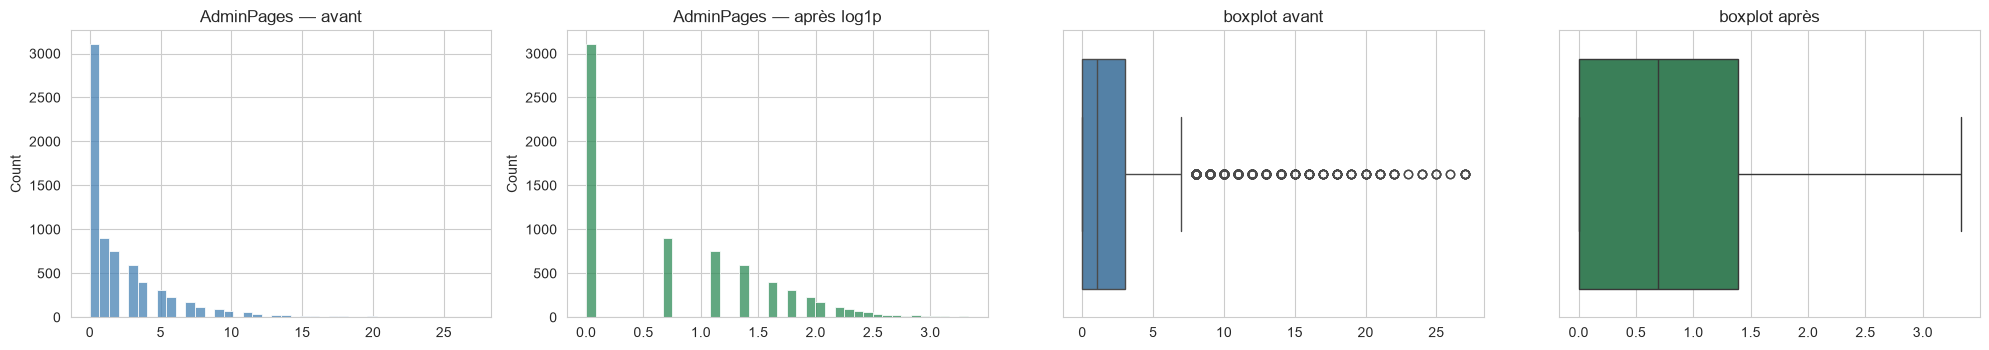

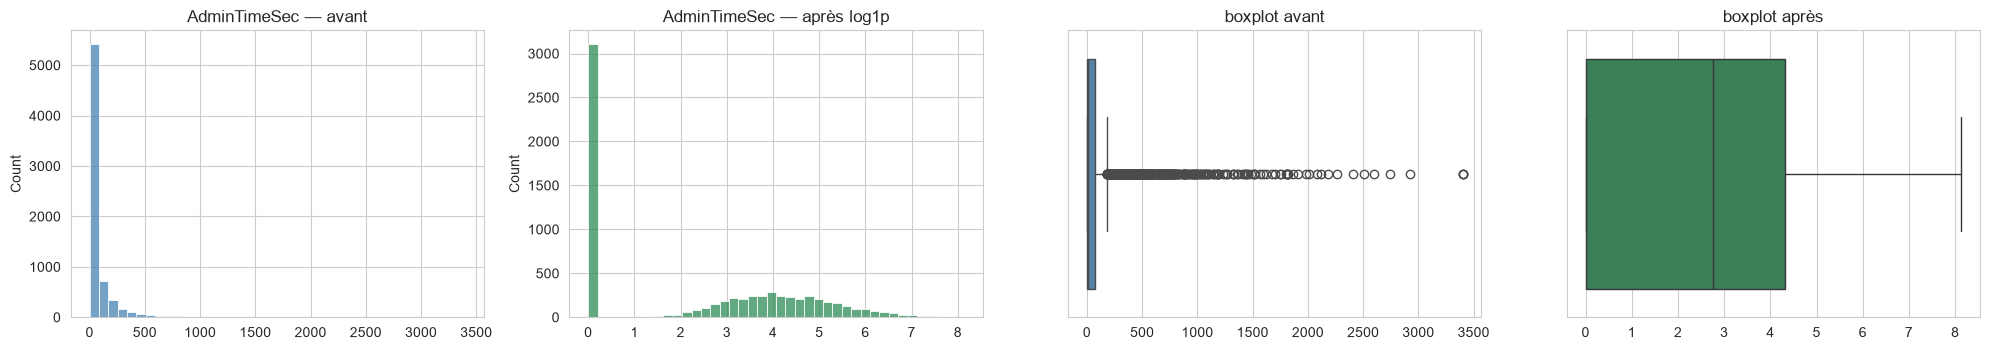

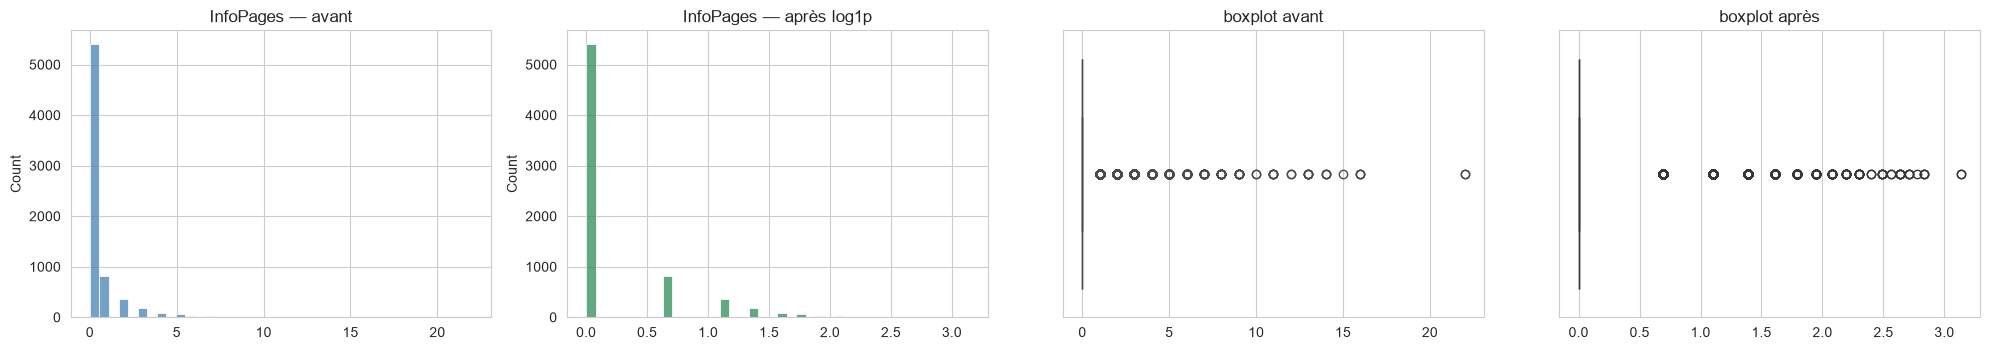

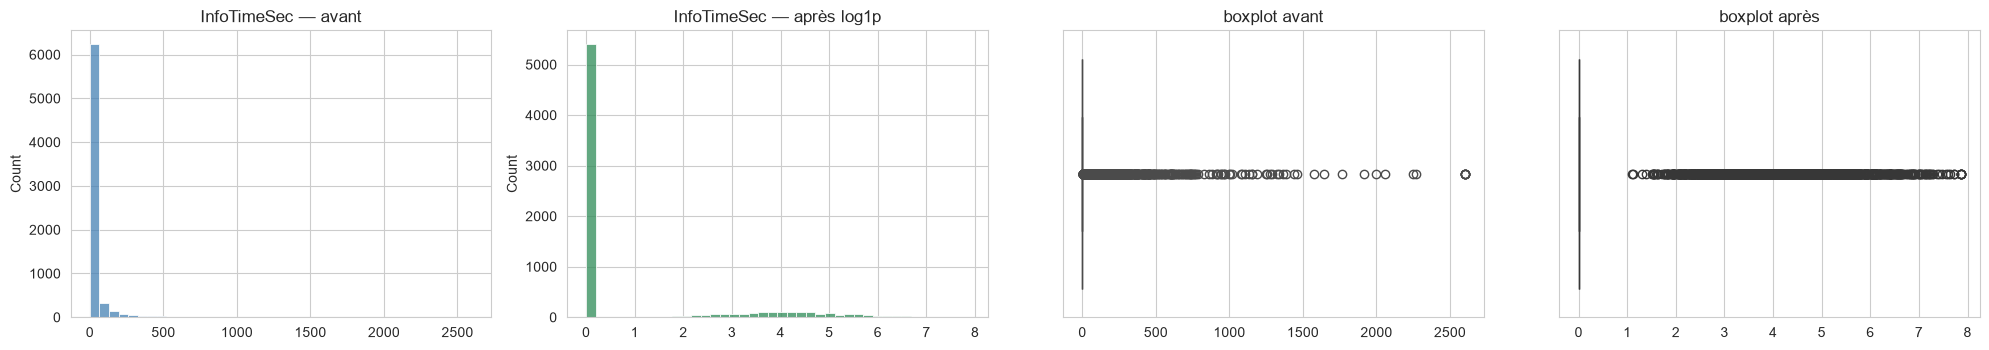

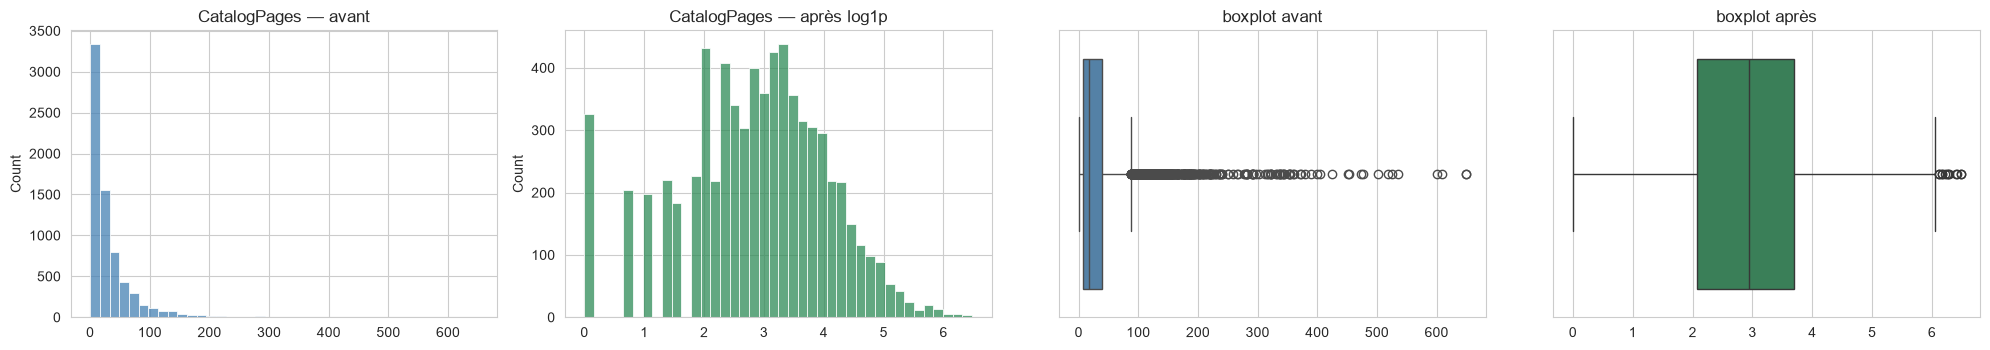

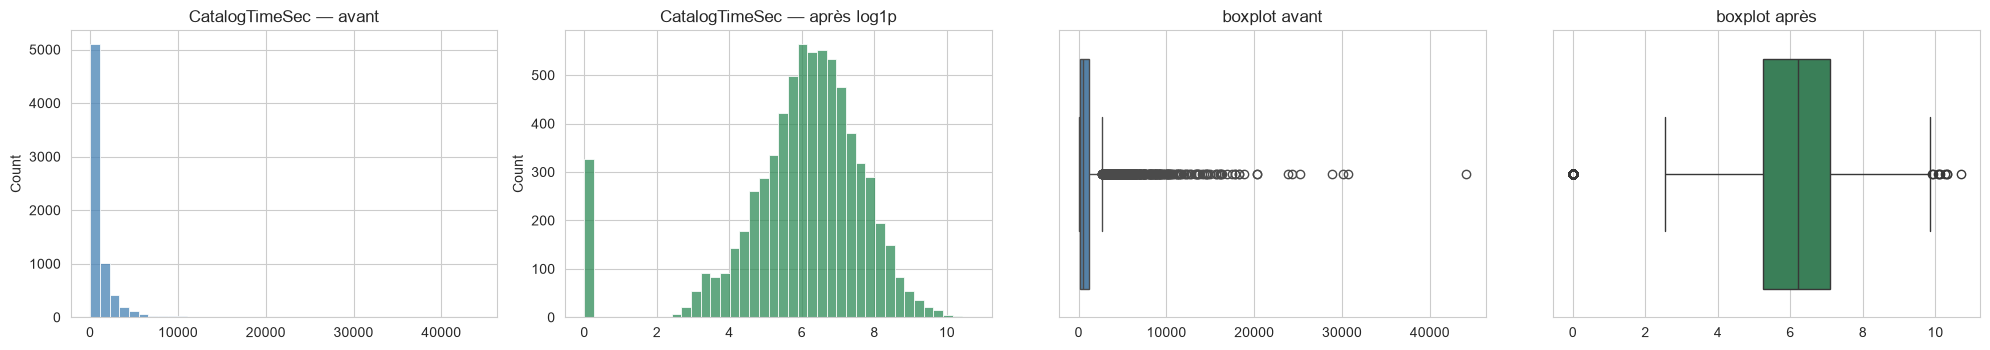

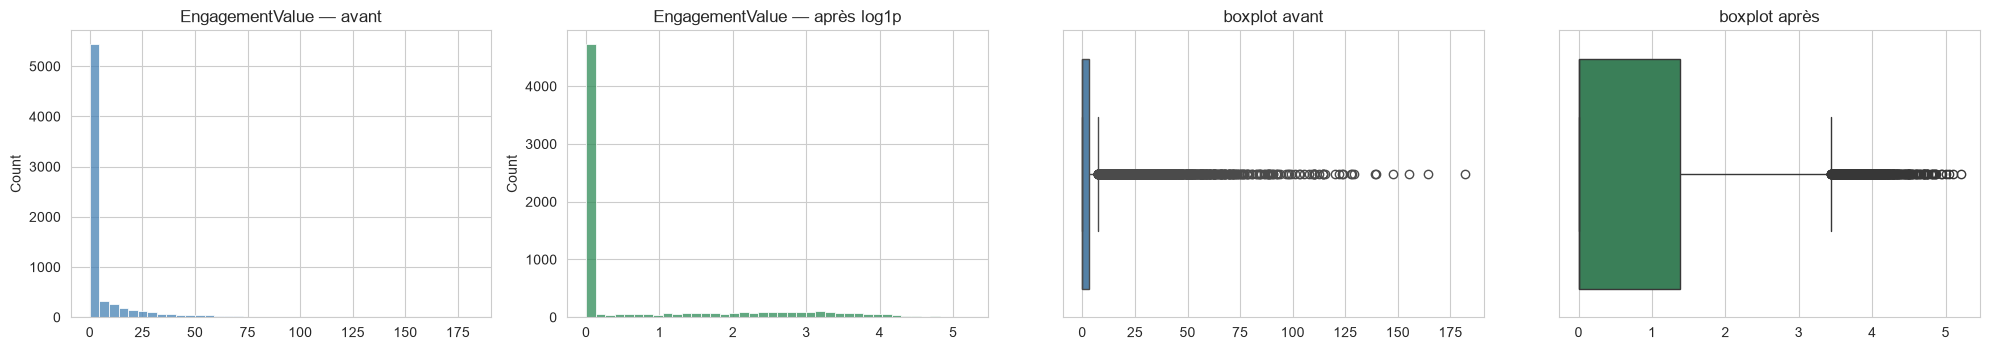

In [13]:

# 9.3 HISTOGRAMMES ET BOXPLOTS AVANT / APRÈS

for c in LOG1P_CANDIDATES:
    s = X_train[c]; t = np.log1p(s)
    fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
    sns.histplot(s, bins=40, ax=axes[0], color="steelblue");  axes[0].set_title(f"{c} — avant")
    sns.histplot(t, bins=40, ax=axes[1], color="seagreen");   axes[1].set_title(f"{c} — après log1p")
    sns.boxplot(x=s, ax=axes[2], color="steelblue");          axes[2].set_title("boxplot avant")
    sns.boxplot(x=t, ax=axes[3], color="seagreen");           axes[3].set_title("boxplot après")
    for a in axes: a.set_xlabel("")
    plt.tight_layout(); plt.show()

Les histogrammes et boxplots confirment que log1p réduit fortement l'asymétrie et comprime les longues queues de AdminTimeSec, InfoTimeSec, CatalogPages, CatalogTimeSec et EngagementValue, tout en préservant les zéros. L'effet est également visible pour AdminPages, mais plus modéré pour InfoPages en raison de sa forte discrétisation et de sa masse de zéros. La transformation ne supprime ni ne modifie la nature des observations extrêmes : elle en réduit principalement l'échelle. La pertinence finale de ces transformations sera donc évaluée par validation croisée.